# CA1 – Machine Learning
## Predicting Maternal Health Risk during Pregnancy

- **Student:** Daniella Silveira e Silva
- **Programme:** HDip in Science in Data Analytics for Business – CCT College Dublin
- **Module:** Machine Learning | **Lecturer:** Dr. Muhammad Iqbal
- **GitHub:** https://github.com/Daniella-CCT/Machine-Learning-Sept26
- **Dataset:** Maternal Health Risk (Ahmed, 2020), UCI Machine Learning Repository – https://archive.ics.uci.edu/dataset/863/maternal+health+risk

This notebook follows the six phases of the **CRISP-DM** methodology (Larose and Larose, 2014): business understanding, data understanding, data preparation, modelling, evaluation and deployment (section 8). All models were built with scikit-learn (Pedregosa et al., 2011).

In [1]:
# ===== Libraries =====
import pandas as pd                 # data handling
import matplotlib.pyplot as plt     # charts
import seaborn as sns               # statistical charts
from scipy import stats             # statistical tests

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")   # hide library warnings to keep the output clean

RANDOM_STATE = 42                   # fixed seed, so the results can be reproduced
sns.set_style("whitegrid")
COLORS = {"low risk": "#4C9F70", "mid risk": "#F2B134", "high risk": "#D1495B"}

## 1. Business understanding

In 2023, about 260,000 women died from complications of pregnancy and childbirth, and most of these deaths were preventable (WHO, 2025). High blood pressure during pregnancy (pre-eclampsia and eclampsia) is one of the main causes. Early identification of high-risk pregnancies helps health workers decide which women need care first, especially in rural areas where women do not see a doctor often.

**Goal:** build classification models that predict the **risk level** of a pregnant woman (low, mid or high) from six vital signs, and find out which signs matter most.

**Questions for this project:**
1. Which features are the most important for predicting the maternal risk level?
2. Which classifier is more suitable for this problem – Random Forest or Support Vector Machine (SVM) – and why?
3. How do the size of the test split and hyperparameter tuning affect accuracy and generalisation?

## 2. Data understanding
### 2.1 Load and describe the dataset

The data was collected from hospitals and community clinics in rural Bangladesh through an IoT-based risk monitoring system (Ahmed et al., 2020). Each row is one pregnant woman.

| Column | Description | Unit |
|---|---|---|
| Age | Age of the woman during pregnancy | years |
| SystolicBP | Upper value of the blood pressure | mmHg |
| DiastolicBP | Lower value of the blood pressure | mmHg |
| BS | Blood sugar (glucose) level | mmol/L |
| BodyTemp | Body temperature | °F |
| HeartRate | Resting heart rate | beats per minute |
| **RiskLevel** | **Target:** risk level during pregnancy | low / mid / high risk |

In [2]:
# Load the dataset (the CSV file must be in the same folder as this notebook)
df = pd.read_csv("maternal_health_risk.csv")

print("Number of rows and columns:", df.shape)
df.head()

Number of rows and columns: (1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# Data types and missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB

Missing values per column:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64


In [4]:
# Summary statistics of the six features
df.describe().round(2)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.00,1014.0,1014.00,1014.00,1014.00,1014.00
mean,29.87,113.2,76.46,8.73,98.67,74.30
std,13.47,18.4,13.89,3.29,1.37,8.09
min,10.00,70.0,49.00,6.00,98.00,7.00
25%,19.00,100.0,65.00,6.90,98.00,70.00
50%,26.00,120.0,80.00,7.50,98.00,76.00
75%,39.00,120.0,90.00,8.00,98.00,80.00
max,70.00,160.0,100.00,19.00,103.00,90.00


**Observations**
- There are 1.014 records, 6 numeric features and 1 categorical target. There are **no missing values.**
- Th minimum **HeartRate is 7 bpm**, which is imossible for a living person. This is a recording error.
- **Age** goes from 10 to 70 years. Some of these ages are very unlikely for a pregnancy (see section 3.3).
- **BodyTemp** is 98°F for most women (the 25th, 50th and 75th percentiles are all 98).

### 2.2 Target variable

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


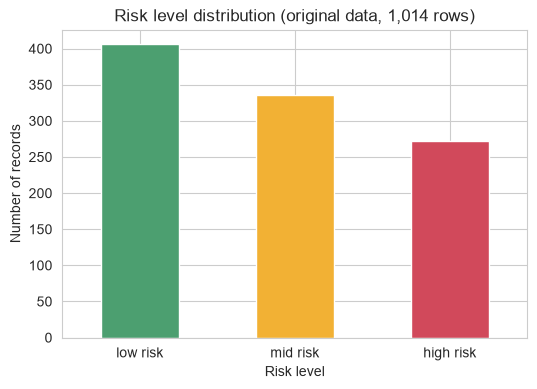

In [8]:
# Distribution of the target variable (risk level)
class_names = ["low risk", "mid risk", "high risk"]
counts = df["RiskLevel"].value_counts()[class_names]
print(counts)

counts.plot(kind="bar", color=[COLORS[c] for c in class_names], figsize=(6, 4))
plt.title(f"Risk level distribution (original data, {len(df):,} rows)")
plt.xlabel("Risk level")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()